# Stochastic Processes
### Understanding Uncertainty

**Worked example:** Bach chorales. **Your analysis:** taxicab trajectories in `data/taxicab.pkl`.

Run the next cell once to download the taxicab data (about 400 MB) into this notebook's folder.

In [1]:
# Download the taxicab data into this notebook's folder (run once).
# On a Mac without wget, use this line instead:
!curl -LO "https://huggingface.co/datasets/ds4e/taxicab/resolve/main/taxicab.pkl"
# !wget -q --show-progress -O taxicab.pkl "https://huggingface.co/datasets/ds4e/taxicab/resolve/main/taxicab.pkl"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1016  100  1016    0     0   8052      0 --:--:-- --:--:-- --:--:--  8063
100  394M  100  394M    0     0  23.3M      0  0:00:16  0:00:16 --:--:-- 38.0M


**Every transition matrix is a conditional PMF but not every PMF is a conditional transition matrix**

***Sequence:*** collection of values ordered by a "time" index

***Stochastic process:*** sequence of random variables

***Markov chain:*** investigation into any change over time, stochastic process where next state is entirely dependent on current

***State space:*** set of values a sequence can take, often grouped into categories, describes every relevant configuration in a system, the modeling decision

## Introduction

- A **stochastic process** is a random phenomenon that changes over time.
- Our workhorse model is the **Markov chain**: the distribution of the next state depends on the current state.
- We will turn sequences into transition counts, conditional probabilities, simulations, and forecasts.
- Bach provides a worked example you can hear and visualize. After each step, apply the same idea to the taxicab data.

1. Sequences and the state space
2. The transition matrix and memory
3. Simulation, forecasting, and a stationary distribution

The music demonstration remains in [`bach.py`](bach.py). Run its sections separately for playback and generated chorales; this notebook uses the same chord cleaning, with numerical summaries and plots. It does not require `music21` or a MIDI player.

# 1. Sequences and the State Space

## Sequences

- A **sequence** is a collection of values ordered by a time or position index.
- Stock prices are indexed by time; a melody is a sequence of notes; text is a sequence of tokens.
- A chorale is a sequence of chords. A taxicab trajectory is a sequence of recorded neighborhoods.
- A stochastic process $\{X_t\}_{t=0}^{T-1}$ models uncertainty about these values.

Our data contain **many separate sequences**. The last chord of one chorale does not lead to the first chord of the next. The same rule applies to separate cab trajectories.

In [2]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from IPython.display import display

sns.set_theme(style='whitegrid')

## Bach and chords

- Music is sound in time. 
- A chord is a set of notes played at the same time.
- Music can be studied and understood **harmonically** as the sequence of chord progressions/changes.
- What chords occur, and how do they evolve from one to another? 

In [3]:
columns = (['song', 'time'] + 
           [str(i) for i in range(1, 13)] + 
           ['root', 'what', 'chord'])


bach_df = pd.read_csv( './bach.data',
                       header=None, names=columns)

# Convert symbols for music21
for old, new in [(' ', ''), ('_', ''), ('M', ''), ('b', '-'),
                 ('d', 'dim'), ('dim6', 'dim'), ('m4', 'm')]:
    bach_df['chord'] = bach_df['chord'].str.replace(old, new, regex=False)

bach_df.head()

,song,time,1,2,3,4,5,6,7,8,9,10,11,12,root,what,chord
0,000106b_,1,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
1,000106b_,2,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,5,C
2,000106b_,3,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,2,C
3,000106b_,4,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
4,000106b_,5,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,2,F


In [4]:
bach_sequences = [
    song.sort_values('time')['chord'].tolist()
    for _, song in bach_df.groupby('song', sort=False)
]

bach_states = sorted({chord for song in bach_sequences for chord in song})

display(bach_df.head(10))
print(f'{len(bach_sequences):,} chorales; {len(bach_df):,} chord observations; '
      f'{len(bach_states):,} distinct chord states')
print('One chorale:', bach_sequences[5][:25])

,song,time,1,2,3,4,5,6,7,8,9,10,11,12,root,what,chord
0,000106b_,1,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
1,000106b_,2,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,5,C
2,000106b_,3,YES,NO,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,E,2,C
3,000106b_,4,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,3,F
4,000106b_,5,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,F,2,F
5,000106b_,6,NO,NO,YES,NO,NO,YES,NO,NO,NO,YES,NO,NO,D,4,Dm
6,000106b_,7,NO,NO,YES,NO,NO,YES,NO,NO,NO,YES,NO,NO,D,2,Dm
7,000106b_,8,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,A,3,F
8,000106b_,9,YES,NO,NO,NO,NO,YES,NO,NO,NO,YES,NO,NO,A,2,F
9,000106b_,10,NO,NO,YES,NO,NO,YES,NO,NO,NO,NO,YES,NO,Bb,5,B-


62 chorales; 5,665 chord observations; 99 distinct chord states
One chorale: ['Gm', 'Gm', 'Gm', 'Gm7', 'Cm', 'Cm7', 'D', 'D7', 'Gm', 'D7', 'Gm', 'Cm7', 'D', 'D', 'Gm', 'Gm', 'F', 'F', 'F', 'B-', 'B-', 'Gm', 'Gm7', 'Cm', 'Cm']


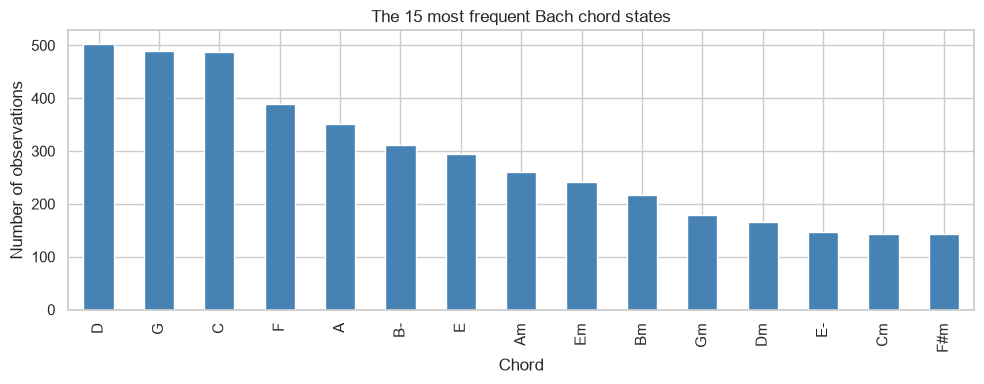

In [5]:
chord_counts = bach_df['chord'].value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
chord_counts.head(15).plot.bar(ax=ax, color='steelblue')
ax.set(title='The 15 most frequent Bach chord states',
       xlabel='Chord', ylabel='Number of observations')
fig.tight_layout()
plt.show()

## States
- A **state** is an irreducible and complete representation of the system
- In the Bach case (from a harmonic perspective), the **state space** is the set of all chords that appear in the corpus of chorales
- For stock prices, it could be a price; for a patient, it could be heart rate; and so on
- The state space is the fundamental concept for Markov chains: We then put a conditional mass function over transitions across the state sapce

## Exercise: taxicab trajectories

- `taxicab.pkl` contains a list of 1,000 cab-days, each holding a sequence of neighborhood labels. 
- The values are the states; the repeated integer indices are neighborhood codes, not timestamps. 
- Load the data and determine the state space.

In [6]:
taxicab_raw = pd.read_pickle('taxicab.pkl')
print(f'Type: {type(taxicab_raw).__name__}; trajectories: {len(taxicab_raw):,}')
print(f'Total recorded observations: {sum(len(trajectory) for trajectory in taxicab_raw):,}')
print('First trajectory (index = neighborhood code):')
display(taxicab_raw[0].head(12))

# .tolist() extracts values in their existing order, without aligning Series indices.
example_trajectory = taxicab_raw[0].iloc[:12].tolist()
print('Values in sequence order:', example_trajectory)

Type: list; trajectories: 1,000
Total recorded observations: 22,963,396
First trajectory (index = neighborhood code):


0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
0     Outside Manhattan
2          Central Park
2          Central Park
34      Upper East Side
34      Upper East Side
35      Upper West Side
Name: nbhd, dtype: object

Values in sequence order: ['Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Outside Manhattan', 'Central Park', 'Central Park', 'Upper East Side', 'Upper East Side', 'Upper West Side']


## Step 1: define the taxicab state space

1. Determine the state space.
2. Build `taxicab_sequences`, a list of separate sequences of labels, and `taxicab_states`, a consistently ordered list of states.
3. Explain what one step means in your model. Keeping consecutive repeats models recorded steps; collapsing them models neighborhood changes. Start by keeping them, then consider how collapsing them changes the question.

Work with a few trajectories first, then scale up. There are nearly 23 million observations; avoid printing them all or concatenating them into one long path.

In [10]:
# Step 1: your inspection and preparation here.
# Keep the outer list: each entry is a separate trajectory or uninterrupted segment.
# taxicab_sequences = ...
# taxicab_states = ...

taxicab_sequences = []
for taxi in taxicab_raw:
    taxicab_sequences.append(taxi.to_list())

taxicab_states = sorted({state for sequence in taxicab_sequences for state in sequence})
len(taxicab_states)

38

# 2. The Transition Matrix

- Once you have a state space, we can imagine changes over that space over time
- Using the expansion trick, we can focus on order-1 transitions over a finite state space
- Then we can capture the system's behavior in a matrix where
    - Each row corresponds to a current state
    - Each column corresponds to a future state
    - The intersection is the probability of the transition


## Moving from state to state

- For states $i$ and $j$, count observed transitions **within** each sequence:
$$
P_{i \rightarrow j} = \dfrac{\frac{1}{T} \sum_{t=0}^{T-1} \mathbb{I}\{ X_{t+1}=j, X_{t}=i\}}{\frac{1}{T} \sum_{t=0}^{T-1} \mathbb{I}\{X_{t}=i\}} = \dfrac{\text{Proportion of transitions from $i$ to $j$}}{\text{Proportion of observations in state $i$}}
$$

- This is called the **transition matrix**, $P$
- Each row $i$ corresponds to a state; each $P_{ij}$ is the probability of transition from $i$ to $j$
- We are estimating a conditional probability,
$$
\text{pr}[X_{t+1}=j | X_t = i] = \dfrac{\text{pr}[X_{t+1}=j \text{ and } X_t = i]}{\text{pr}[ X_t = i]} = \dfrac{\text{joint}}{\text{marginal}}
$$


**Our convention throughout:** rows are **from**, columns are **to**. Each row with observed departures sums to one. A row without departures contains zeros: the data do not tell us what happens next from that state.

**Sequence is a markov chain if state depends on the past only through the current state; memoryless. Given where you are now, how you got there is irrelevant.**

***Time homogeneity:*** conditional probability is the same for every t, similar to identically distrbuted, but in time

In [11]:
#last week we used pd.crosstab, but now our data are variable length sequences and very large --> vectorize
#code we would have used last week
# def transition_table(sequences, states, normalize=False):
#     """Cross-tabulate (current, next) pairs within each sequence; rows = from, columns = to."""
#     # Work with each state's position, so pair states such as ('C', 'Am') stay single labels.
#     position = {state: i for i, state in enumerate(states)}
#     current = [position[state] for sequence in sequences for state in sequence[:-1]]
#     following = [position[state] for sequence in sequences for state in sequence[1:]]
#     table = pd.crosstab(pd.Series(current, name='from'), pd.Series(following, name='to'),
#                         normalize='index' if normalize else False)
    
#     # States never seen as a 'from' (or 'to') get a row (or column) of zeros.
#     positions = range(len(states))
#     table = table.reindex(index=positions, columns=positions, fill_value=0)
#     labels = pd.Index(states, tupleize_cols=False)
#     table.index, table.columns = labels.rename('from'), labels.rename('to')
#     return table

## Basic Vectorized Approach

# Transition dictionary:
state_index = {state: i for i, state in enumerate(bach_states)}

# Compute counts:
counts = np.zeros((len(bach_states), len(bach_states)), dtype=np.int32)
for song in bach_sequences:
    indices = np.array([state_index[state] for state in song], dtype=int)
    np.add.at(counts, (indices[:-1], indices[1:]), 1) # Vectorized pairwise counting

# Compute transition probabilities:
bach_P = counts / counts.sum(axis=1)[:, None] # Transition matrix


In [12]:

## Breaking the task into functions, with more guardrails

def transition_counts(sequences, states):
    """Count adjacent pairs within each sequence; rows = from, columns = to."""
    state_index = {state: i for i, state in enumerate(states)}
    counts = np.zeros((len(states), len(states)), dtype=np.int64)
    for sequence in sequences:
        # A length-zero or length-one sequence contributes no transitions.
        indices = np.array([state_index[state] for state in sequence], dtype=int)
        np.add.at(counts, (indices[:-1], indices[1:]), 1)
    return counts


def transition_probabilities(counts):
    departures = counts.sum(axis=1, keepdims=True)
    return np.divide(counts, departures,
                     out=np.zeros_like(counts, dtype=float), where=departures != 0)



In [13]:
bach_counts = transition_counts(bach_sequences, bach_states)
bach_P = transition_probabilities(bach_counts)

In [14]:
# First seven rows/columns
common_chords = chord_counts.head(7).index.tolist()
bach_P_df = pd.DataFrame(bach_P, index=bach_states, columns=bach_states)
display(bach_P_df.loc[common_chords, common_chords].round(3))

,D,G,C,F,A,B-,E
D,0.444,0.186,0.016,0.004,0.073,0.002,0.026
G,0.103,0.458,0.211,0.008,0.006,0.002,0.010
C,0.035,0.127,0.504,0.122,0.006,0.004,0.010
F,0.013,0.021,0.120,0.470,0.000,0.180,0.000
A,0.219,0.009,0.006,0.003,0.461,0.000,0.064
B-,0.023,0.003,0.026,0.127,0.000,0.519,0.003
E,0.004,0.000,0.004,0.018,0.179,0.000,0.418


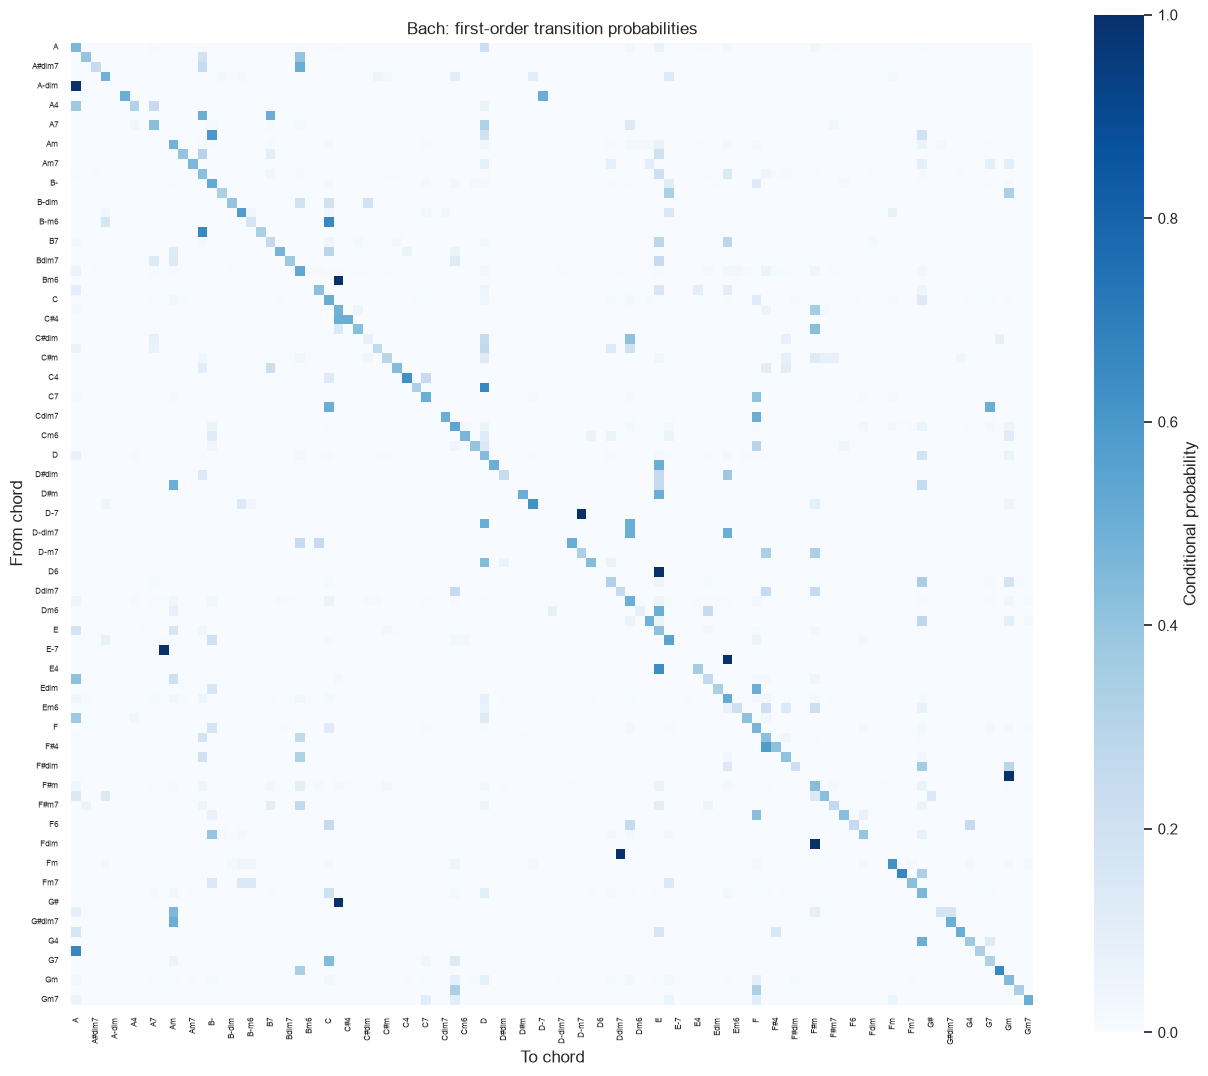

In [15]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(bach_P_df, cmap='Blues', square=True,
            cbar_kws={'label': 'Conditional probability'}, ax=ax)
ax.set(title='Bach: first-order transition probabilities',
       xlabel='To chord', ylabel='From chord')
ax.tick_params(axis='x', labelrotation=90, labelsize=6)
ax.tick_params(axis='y', labelrotation=0, labelsize=6)
fig.tight_layout()
plt.show()

## Counts and conditional probabilities answer different questions

A frequent route can have a large count because its origin is common. A large conditional probability means a destination is likely **given that origin**, even if the origin is rare.

Read a row of the heatmap as a distribution of destinations. A blank cell means the transition was not observed; it does not establish that the transition is impossible.

In [16]:
from_indices, to_indices = np.nonzero(bach_counts)
bach_routes = pd.DataFrame({
    'from': [bach_states[i] for i in from_indices],
    'to': [bach_states[j] for j in to_indices],
    'count': bach_counts[from_indices, to_indices],
    'probability': bach_P[from_indices, to_indices],
})
display(bach_routes.sort_values('count', ascending=False).head(10).round(3))

current_chord = 'C'
print(f'Most likely next chords given {current_chord}:')
display(bach_P_df.loc[current_chord].sort_values(ascending=False).head(8).round(3))

,from,to,count,probability
229,C,C,243,0.504
352,D,D,220,0.444
694,G,G,219,0.458
563,F,F,180,0.470
126,B-,B-,160,0.519
0,A,A,158,0.461
524,Em,Em,125,0.519
63,Am,Am,124,0.477
472,E,E,119,0.418
190,Bm,Bm,115,0.530


Most likely next chords given C:


C      0.504
G      0.127
F      0.122
D      0.035
Am     0.029
Dm     0.023
Dm7    0.019
D7     0.017
Name: C, dtype: float64

## Exercise: estimate taxicab transitions

1. Use your prepared sequences to compute `taxicab_counts` and `taxicab_P` with the same row convention as Bach.
2. Plot a labeled heatmap. Compare the routes with the largest **counts** with destinations having the largest **conditional probabilities** from a selected origin. Report how many observations support each claim.

Do not join the end of one trajectory to the beginning of another. Keep one state order for your counts, probabilities, plots, and forecasts.

In [24]:
# Step 2: counts, heatmap, and route comparisons here.
taxicab_counts = transition_counts(taxicab_sequences, taxicab_states)
taxicab_P = transition_probabilities(taxicab_counts)

taxicab_P_df = pd.DataFrame(taxicab_P, index=taxicab_states, columns=taxicab_states)

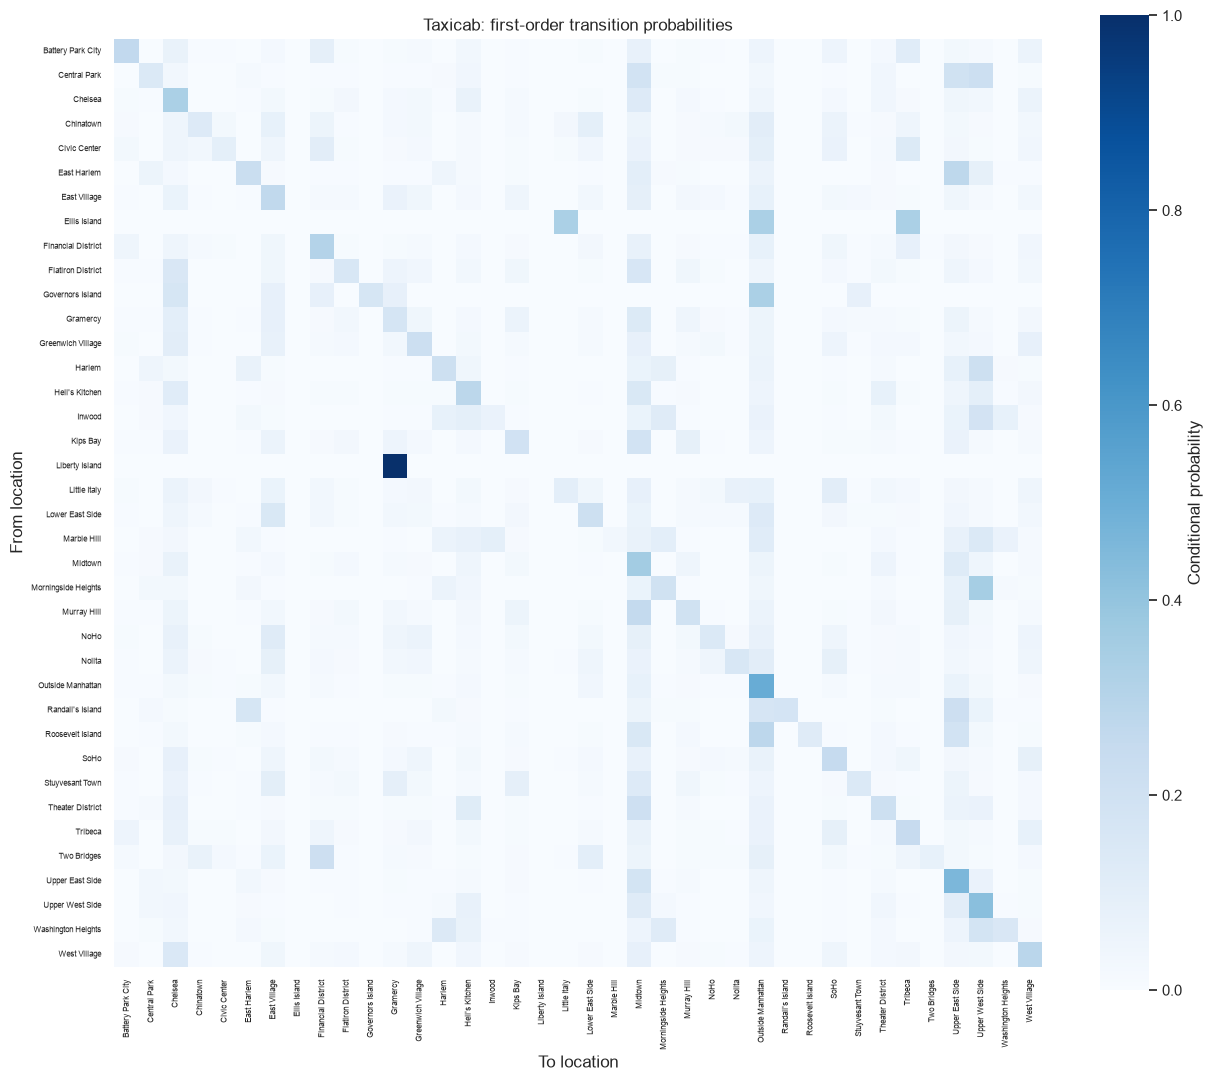

In [25]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(taxicab_P_df, cmap='Blues', square=True,
            cbar_kws={'label': 'Conditional probability'}, ax=ax)
ax.set(title='Taxicab: first-order transition probabilities',
       xlabel='To location', ylabel='From location')
ax.tick_params(axis='x', labelrotation=90, labelsize=6)
ax.tick_params(axis='y', labelrotation=0, labelsize=6)
fig.tight_layout()
plt.show()

# The order of a chain

- In many systems, a naive definition of state can be misleading
- In a song, the sequence of chords typically exhibits dependence over more than one change: A common progression is I-V-vi-IV, for example
- In that case, we **expand the state space** and represent the state as a tuple, so the sequence `C → Am → Dm → G` becomes `(C, Am) → (Am, Dm) → (Dm, G)`.
- The number of lagged values included is called the **order** of the chain
- If the original state space has $K$ elements, then the order $O$ expansion has $K^O$ elements: This is a curse of dimensionality 
- The transformer is a way to address the curse of dimensionality with sequences with high order dependence on previous values

**How much memory do you want to include?**

Markov chain must be memoryless.

If past states do matter, we just add more past days into our current state

Order of a chain is how much of the past we include in the markov chain

As we increase the order, number of states increase but moves per states decrease. A lot of transition matrix will be 0 (sparse matrix)

With low order, we have bias (underfitting), high orders have more variance and may be overfit

In [26]:
## Convert to pairwise transitions
bach_pair_sequences = [
    list(
        zip(song[:-1], song[1:]) #zip the current and previous into a single state
    ) for song in bach_sequences #for each song in our sequences list
]
## Compute counts and probabilities for pairwise transitions
bach_pair_states = sorted({pair for song in bach_pair_sequences for pair in song}) #get all the states
bach_pair_counts = transition_counts(bach_pair_sequences, bach_pair_states)
bach_pair_P = transition_probabilities(bach_pair_counts)

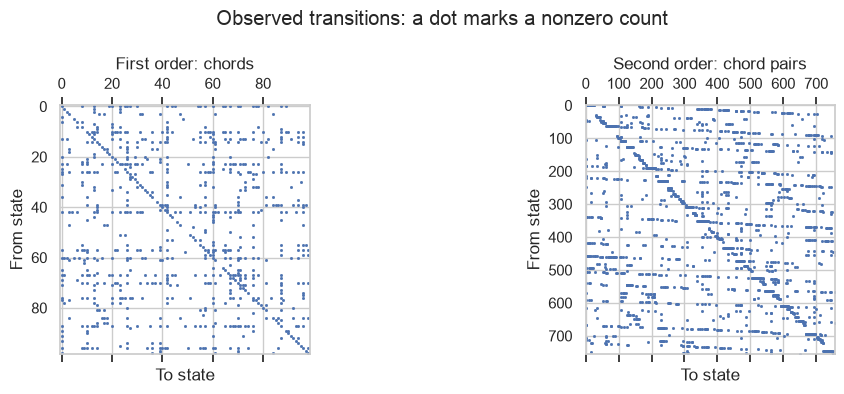

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title in zip(axes, [bach_counts, bach_pair_counts],
                              ['First order: chords', 'Second order: chord pairs']):
    ax.spy(counts, markersize=1)
    ax.set(title=title, xlabel='To state', ylabel='From state')
fig.suptitle('Observed transitions: a dot marks a nonzero count')
fig.tight_layout()
plt.show()

## Sparse versus dense

Most entries of the pair-state matrix are zero. Some are structurally impossible: `(C, Am)` can only transition to a pair beginning with `Am`. Others may be absent because our sample is small.

A **sparse** representation stores the nonzero entries rather than every matrix cell. We use dense arrays here because the example is manageable; a larger state space may require sparse storage.

Keep `bach_P` and `bach_pair_P` separate. We will use the first-order model for forecasting, where every Bach state has observed departures.

## Connectivity: Can every state reach every other state?

A directed chain is **strongly connected** (irreducible) if every state can reach every other state along a path of positive-probability transitions. A direct transition is not required.

The observed transition graph helps us inspect this property. Missing paths in a finite sample are evidence about the fitted model, not proof that travel or a chord progression is impossible in the world.

**Reachable if one state has a path (doesn't have to be direct) to another**

**Strongly connected (irreducible) if every state is reachable from all other states**

**Weakly connected if directed graph has no way to traverse back**

**State is absorbing if once there the chain does not leave**

In [28]:
for name, counts in [('Bach chords', bach_counts), ('Bach chord pairs', bach_pair_counts)]:
    graph = nx.from_numpy_array(counts > 0, create_using=nx.DiGraph)
    components = list(nx.strongly_connected_components(graph))
    print(f'{name}: strongly connected = {nx.is_strongly_connected(graph)}; '
          f'components = {len(components)}; '
          f'largest component = {max(map(len, components))} states')

Bach chords: strongly connected = True; components = 1; largest component = 99 states
Bach chord pairs: strongly connected = False; components = 15; largest component = 743 states


## Exercise: memory and connectivity in taxicab data

1. Is the current neighborhood enough to predict the next one? Give reasons a previous neighborhood, time of day, or driver behavior might matter. First order is a modeling assumption to assess.
2. Construct the directed graph of your observed transitions. Is it strongly connected? If not, identify the components and any states without departures.
3. Optional: estimate a second-order model on a subset of trajectories. Compare its number of states, sparsity, and counts per state with the first-order model. How would you check whether the extra memory improves prediction on held-out trajectories?

In [ ]:
# Step 3: connectivity and evidence about memory here.

# 3. Simulation

## Simulation

With the state space and transition matrix, we have everything we need to simulate the chain:

1. Pick an initial state.
2. Each row of `bach_P` gives the probabilities of the next chord, conditional on the current chord. Draw from that row, move to the new state.
3. Repeat step 2.

In [ ]:
def simulate(states, probabilities, initial_state, n_steps, seed=100):
    rng = np.random.default_rng(seed)
    index = states.index(initial_state)
    path = [initial_state]
    for _ in range(n_steps):
        outgoing = probabilities[index]
        if outgoing.sum() == 0:
            print(f'No observed departures from {states[index]!r}; stopping.')
            break
        index = rng.choice(len(states), p=outgoing)
        path.append(states[index])
    return path

In [ ]:
bach_simulation = simulate(bach_states, bach_P, initial_state='C', n_steps=20)
rng = np.random.default_rng(100)
independent_chords = rng.choice(
    bach_states, size=21,
    p=chord_counts.reindex(bach_states).to_numpy() / chord_counts.sum(),
).tolist()
print('Independent chords:', ' → '.join(independent_chords))
print('First-order chain:', ' → '.join(bach_simulation))

## Exercise: Simulate taxicab locations

1. Choose any neighborhood and simulate the first 10 transitions using your Markov chain. 
2. Repeat step 1, for 100 transitions, caching the final result.
3. Repeat step 2 five hundred times, and plot the probability mass function over neighborhoods. 
4. Choose any neighborhood and repeat the above. Compare the probability mass functions. Are they similar or significantly different?

In [ ]:
# Exercise 4: simulation, forecasts, and interpretation here.